# Licenta agri

Import biblioteci si setul de date

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

file_path = "dataset/date_senzori_BEIA.xlsx"

raw_sheets = pd.read_excel(
    file_path,
    sheet_name=None
)

raw_sheets.pop("Sumar", None)

print(f"Numar foi: {len(raw_sheets)}")

for name, df in raw_sheets.items():
    print(f"{name}: {len(df):,} rows")

Numar foi: 12
temperature: 48,514 rows
humidity: 48,514 rows
pressure: 48,514 rows
pressure_vapor: 48,514 rows
radiation: 48,514 rows
precipitation: 48,514 rows
wind_speed: 48,514 rows
vane_direction: 48,514 rows
temperature_depth_0: 16,618 rows
temperature_depth_1: 16,618 rows
temperature_depth_5: 16,612 rows
moisture_w-o_salinity_depth_5: 16,612 rows


Raport Data Quality

In [3]:
audit = []

for name, df in raw_sheets.items():
    time_values = pd.to_datetime(
        df["time"], errors="coerce"
    )
    
    numeric_values = pd.to_numeric(
        df["value"], errors="coerce"
    )

    audit.append({
        "sheet": name,
        "rows": len(df),
        "null_values": numeric_values.isna().sum(),
        "null_time": time_values.isna().sum(),
        "duplicates": time_values.duplicated().sum(),
        "min": numeric_values.min(),
        "max": numeric_values.max(),
        "mean": numeric_values.mean(),
        "first_reading": time_values.min(),
        "last_reading": time_values.max()
    })

audit_df = pd.DataFrame(audit)

display(audit_df)

,sheet,rows,null_values,null_time,duplicates,min,max,mean,first_reading,last_reading
0,temperature,48514,0,0,0,-2.700,37.800,15.854382,2025-07-14 12:51:47,2026-07-14 09:41:13
1,humidity,48514,0,0,0,15.100,100.000,69.879179,2025-07-14 12:51:47,2026-07-14 09:41:13
2,pressure,48514,0,0,0,96.300,99.880,98.340164,2025-07-14 12:51:47,2026-07-14 09:41:13
3,pressure_vapor,48514,0,0,0,0.294,3.057,1.278200,2025-07-14 12:51:47,2026-07-14 09:41:13
4,radiation,48514,0,0,0,209.249,1111.287,323.950451,2025-07-14 12:51:47,2026-07-14 09:41:13
5,precipitation,48514,0,0,0,0.000,8.400,0.009304,2025-07-14 12:51:47,2026-07-14 09:41:13
6,wind_speed,48514,0,0,0,0.000,43.200,3.503648,2025-07-14 12:51:47,2026-07-14 09:41:13
7,vane_direction,48514,0,0,0,0.000,315.000,171.708476,2025-07-14 12:51:47,2026-07-14 09:41:13
8,temperature_depth_0,16618,0,0,0,-6.810,46.240,14.338679,2025-07-14 12:20:28,2026-07-14 08:54:56
9,temperature_depth_1,16618,0,0,0,-6.710,46.270,14.243425,2025-07-14 12:20:28,2026-07-14 08:54:56


Verificare intervale dintre citiri

In [4]:
frequency_report = []

for name, df in raw_sheets.items():

    timestamps = pd.to_datetime(
        df["time"], errors="coerce"
    ).dropna().sort_values()

    intervals = (
        timestamps.diff()
        .dropna()
        .dt.total_seconds() / 60
    )

    frequency_report.append({
        "sheet": name,
        "median_interval_min": intervals.median(),
        "min_interval_min": intervals.min(),
        "max_interval_min": intervals.max(),
        "intervals_under_15_min": (intervals < 15).sum(),
        "intervals_over_60_min": (intervals > 60).sum()
    })

frequency_df = pd.DataFrame(frequency_report)

display(frequency_df.round(2))

,sheet,median_interval_min,min_interval_min,max_interval_min,intervals_under_15_min,intervals_over_60_min
0,temperature,5.0,0.62,137544.42,37342,7
1,humidity,5.0,0.62,137544.42,37342,7
2,pressure,5.0,0.62,137544.42,37342,7
3,pressure_vapor,5.0,0.62,137544.42,37342,7
4,radiation,5.0,0.62,137544.42,37342,7
5,precipitation,5.0,0.62,137544.42,37342,7
6,wind_speed,5.0,0.62,137544.42,37342,7
7,vane_direction,5.0,0.62,137544.42,37342,7
8,temperature_depth_0,5.0,3.82,127850.08,10782,1714
9,temperature_depth_1,5.0,3.82,127850.08,10782,1714


Distributia intervalelor dintre citiri

In [5]:
for name in ["temperature", "temperature_depth_0"]:

    df = raw_sheets[name].copy()

    df["time"] = pd.to_datetime(df["time"])

    intervals = (
        df.sort_values("time")["time"]
        .diff()
        .dt.total_seconds()
        .div(60)
        .dropna()
    )

    print(f"\n{name}")
    print("Top 10 intervale (minute):")
    print(intervals.round(1).value_counts().head(10))


temperature
Top 10 intervale (minute):
time
5.0     32900
15.0    12187
4.9       729
14.6      590
4.6       492
15.2      241
5.2       224
15.4      215
5.3       179
15.3      145
Name: count, dtype: int64

temperature_depth_0
Top 10 intervale (minute):
time
5.0     10232
60.0     2974
15.0     1291
59.6      599
60.3      304
60.2      271
4.6       153
60.4      148
59.7      143
5.2        66
Name: count, dtype: int64


Identificare intreruperi mari

In [6]:
for name in ["temperature", "temperature_depth_0"]:

    df = raw_sheets[name].copy()

    df["time"] = pd.to_datetime(df["time"])
    df = df.sort_values("time")

    df["gap_minutes"] = (
        df["time"].diff().dt.total_seconds() / 60
    )

    gaps = df.loc[
        df["gap_minutes"] > 60,
        ["time", "gap_minutes"]
    ].copy()

    gaps["gap_hours"] = gaps["gap_minutes"] / 60

    print(f"\n{name} - intreruperi peste o ora:")
    print(f"Total: {len(gaps)}")

    display(
        gaps.sort_values(
            "gap_minutes",
            ascending=False
        ).head(10)
    )


temperature - intreruperi peste o ora:
Total: 7


,time,gap_minutes,gap_hours
12765,2026-03-03 06:56:14,137544.416667,2292.406944
13657,2025-11-18 10:45:33,3724.666667,62.077778
13756,2025-11-15 12:31:26,2285.083333,38.084722
13894,2025-11-13 11:01:39,1325.066667,22.084444
22576,2025-10-13 09:25:48,1265.133333,21.085556
12733,2026-03-03 20:23:11,344.216667,5.736944
13516,2025-11-19 22:45:07,60.016667,1.000278



temperature_depth_0 - intreruperi peste o ora:
Total: 1714


,time,gap_minutes,gap_hours
9695,2025-11-04 07:53:05,127850.083333,2130.834722
399,2026-06-27 15:59:55,51739.833333,862.330556
384,2026-06-28 08:59:03,179.900000,2.998333
376,2026-06-28 17:01:03,62.100000,1.035000
1395,2026-04-11 06:49:27,61.800000,1.030000
1080,2026-04-24 09:47:18,61.733333,1.028889
3723,2026-01-04 07:01:32,61.716667,1.028611
4063,2025-12-21 03:02:44,61.650000,1.027500
2513,2026-02-23 16:56:03,61.583333,1.026389
2860,2026-02-09 05:57:53,61.550000,1.025833


Suprapunere temporala

In [7]:
meteo_times = set(
    pd.to_datetime(raw_sheets["temperature"]["time"])
)

soil_times = set(
    pd.to_datetime(raw_sheets["temperature_depth_0"]["time"])
)

common_times = meteo_times & soil_times

print("Timestampuri meteo:", len(meteo_times))
print("Timestampuri sol:", len(soil_times))
print("Timestampuri comune:", len(common_times))

print(
    "Procent de citiri sol sincronizate exact:",
    round(len(common_times) / len(soil_times) * 100, 2),
    "%"
)

Timestampuri meteo: 48514
Timestampuri sol: 16618
Timestampuri comune: 36
Procent de citiri sol sincronizate exact: 0.22 %


Proximitate temporala 

In [8]:
meteo = raw_sheets["temperature"][["time"]].copy()
soil = raw_sheets["temperature_depth_0"][["time"]].copy()
meteo["time"] = pd.to_datetime(meteo["time"])
soil["time"] = pd.to_datetime(soil["time"])
meteo = meteo.sort_values("time").rename(columns={"time": "meteo_time"})
soil = soil.sort_values("time").rename(columns={"time": "soil_time"})
matches = pd.merge_asof(
    soil,
    meteo,
    left_on="soil_time",
    right_on="meteo_time",
    direction="nearest"
)
matches["difference_minutes"] = (
    (matches["soil_time"] - matches["meteo_time"])
    .abs()
    .dt.total_seconds() / 60
)
for tolerance in [1, 2, 5, 10, 15, 30, 60]:
    count = (matches["difference_minutes"] <= tolerance).sum()
    percentage = count / len(matches) * 100
    print(f"±{tolerance:2} min: {count:6} citiri ({percentage:.2f}%)")

± 1 min:   5654 citiri (34.02%)
± 2 min:  10281 citiri (61.87%)
± 5 min:  12737 citiri (76.65%)
±10 min:  12743 citiri (76.68%)
±15 min:  12752 citiri (76.74%)
±30 min:  12776 citiri (76.88%)
±60 min:  12811 citiri (77.09%)


Distributia dif temp

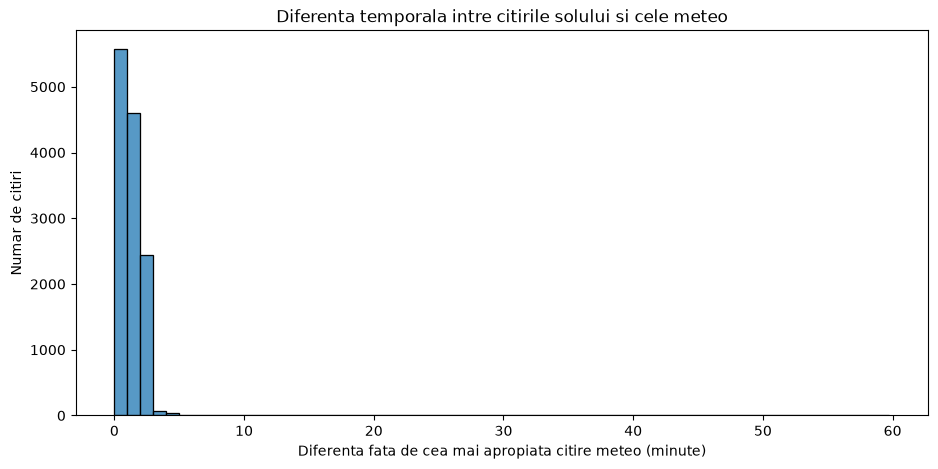

In [9]:
plt.figure(figsize=(11, 5))
sns.histplot(
    matches.loc[
        matches["difference_minutes"] <= 60,
        "difference_minutes"
    ],
    bins=60
)
plt.title("Diferenta temporala intre citirile solului si cele meteo")
plt.xlabel("Diferenta fata de cea mai apropiata citire meteo (minute)")
plt.ylabel("Numar de citiri")
plt.show()

Raport de outlieri folosind IQR

In [10]:
outlier_report = []
for name, df in raw_sheets.items():
    values = pd.to_numeric(df["value"], errors="coerce")
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = (values < lower_bound) | (values > upper_bound)
    outlier_report.append({
        "sheet": name,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outliers": outliers.sum(),
        "outlier_pct": outliers.mean() * 100
    })
outlier_df = pd.DataFrame(outlier_report)
display(outlier_df.round(2))

,sheet,lower_bound,upper_bound,outliers,outlier_pct
0,temperature,-6.75,37.65,1,0.00
1,humidity,4.35,136.75,0,0.00
2,pressure,96.92,99.80,478,0.99
3,pressure_vapor,-0.23,2.80,1,0.00
4,radiation,10.98,565.43,6153,12.68
5,precipitation,0.00,0.00,960,1.98
6,wind_speed,-5.20,10.80,2512,5.18
7,vane_direction,-180.00,540.00,0,0.00
8,temperature_depth_0,-19.12,45.20,4,0.02
9,temperature_depth_1,-19.27,45.13,5,0.03


Boxplot pentru temperaturile din sol și aer

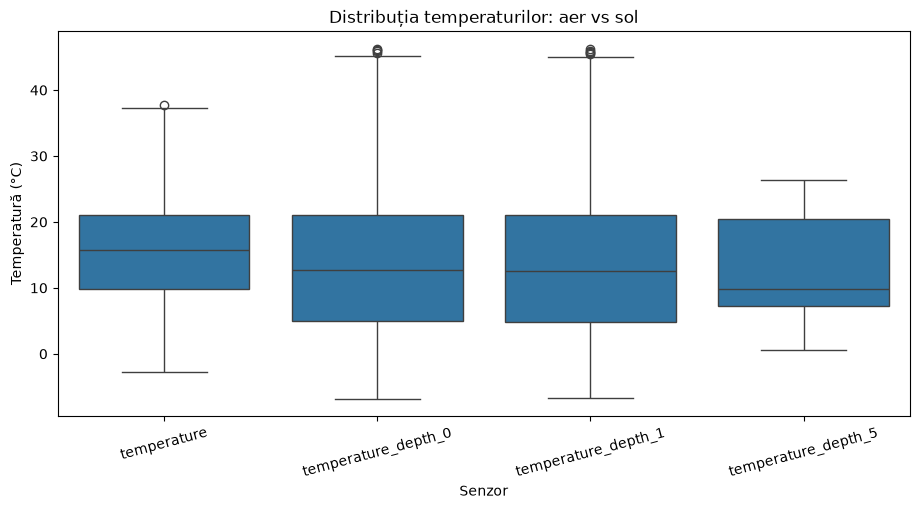

In [11]:
temp_sheets = [
    "temperature",
    "temperature_depth_0",
    "temperature_depth_1",
    "temperature_depth_5"
]
temp_data = pd.concat([
    pd.DataFrame({
        "sensor": name,
        "value": raw_sheets[name]["value"]
    })
    for name in temp_sheets
], ignore_index=True)
plt.figure(figsize=(11, 5))
sns.boxplot(data=temp_data, x="sensor", y="value")
plt.title("Distribuția temperaturilor: aer vs sol")
plt.xlabel("Senzor")
plt.ylabel("Temperatură (°C)")
plt.xticks(rotation=15)
plt.show()

# Standardizarea datelor

In [12]:
clean_sheets = {}
for name, df in raw_sheets.items():
    clean = df.copy()
    clean.columns = clean.columns.str.strip().str.lower()
    clean["time"] = pd.to_datetime(clean["time"], errors="coerce")
    clean["value"] = pd.to_numeric(clean["value"], errors="coerce")
    clean = clean.sort_values("time").reset_index(drop=True)
    clean_sheets[name] = clean
for name, df in clean_sheets.items():
    print(name, df.shape, df["value"].isna().sum())

temperature (48514, 6) 0
humidity (48514, 6) 0
pressure (48514, 6) 0
pressure_vapor (48514, 6) 0
radiation (48514, 6) 0
precipitation (48514, 6) 0
wind_speed (48514, 6) 0
vane_direction (48514, 6) 0
temperature_depth_0 (16618, 6) 0
temperature_depth_1 (16618, 6) 0
temperature_depth_5 (16612, 6) 0
moisture_w-o_salinity_depth_5 (16612, 6) 0


Validare fizica

In [13]:
physical_ranges = {
    "humidity": (0, 100),
    "precipitation": (0, None),
    "wind_speed": (0, None),
    "vane_direction": (0, 360),
    "pressure_vapor": (0, None),
    "moisture_w-o_salinity_depth_5": (0, 100)
}
validation_results = []
for name, (lower, upper) in physical_ranges.items():
    df = clean_sheets[name]
    values = df["value"]
    invalid = pd.Series(False, index=df.index)
    if lower is not None:
        invalid |= values < lower
    if upper is not None:
        invalid |= values > upper
    validation_results.append({
        "sheet": name,
        "invalid_values": int(invalid.sum()),
        "min": values.min(),
        "max": values.max()
    })
validation_df = pd.DataFrame(validation_results)
display(validation_df)

,sheet,invalid_values,min,max
0,humidity,0,15.100,100.000
1,precipitation,0,0.000,8.400
2,wind_speed,0,0.000,43.200
3,vane_direction,0,0.000,315.000
4,pressure_vapor,0,0.294,3.057
5,moisture_w-o_salinity_depth_5,0,18.570,64.630


Consistenta datelor

In [14]:
metadata_report = []
for name, df in clean_sheets.items():
    metadata_report.append({
        "sheet": name,
        "devices": df["device"].nunique(dropna=False),
        "measures": df["measure"].nunique(dropna=False),
        "units": df["units"].nunique(dropna=False),
        "probe_serials": df["probe_serial"].nunique(dropna=False),
        "time_duplicates": df["time"].duplicated().sum()
    })
metadata_df = pd.DataFrame(metadata_report)
display(metadata_df)

,sheet,devices,measures,units,probe_serials,time_duplicates
0,temperature,1,1,1,1,0
1,humidity,1,1,1,1,0
2,pressure,1,1,1,1,0
3,pressure_vapor,1,1,1,1,0
4,radiation,1,1,1,1,0
5,precipitation,1,1,1,1,0
6,wind_speed,1,1,1,1,0
7,vane_direction,1,1,1,1,0
8,temperature_depth_0,1,1,1,1,0
9,temperature_depth_1,1,1,1,1,0


## Fact Table (fara a modifica masuratorile)

In [15]:
from functools import reduce

tables = []
for sheet_name, df in clean_sheets.items():
    temp = df[["time", "value"]].copy()
    temp = temp.rename(columns={"value": sheet_name})
    tables.append(temp)
fact_agriculture_raw = reduce(
    lambda left, right: pd.merge(
        left, right,
        on="time",
        how="outer",
        validate="one_to_one"
    ),
    tables
)
fact_agriculture_raw = (
    fact_agriculture_raw
    .sort_values("time")
    .reset_index(drop=True)
)
fact_agriculture_raw.insert(
    0,
    "FactID",
    range(1, len(fact_agriculture_raw) + 1)
)
display(fact_agriculture_raw.head(10))
print("Dimensiune:", fact_agriculture_raw.shape)

,FactID,time,temperature,humidity,pressure,pressure_vapor,radiation,precipitation,wind_speed,vane_direction,temperature_depth_0,temperature_depth_1,temperature_depth_5,moisture_w-o_salinity_depth_5
0,1,2025-07-14 12:20:28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31.84,31.85,NaN,NaN
1,2,2025-07-14 12:25:31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31.95,31.90,NaN,NaN
2,3,2025-07-14 12:30:28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31.29,31.31,NaN,NaN
3,4,2025-07-14 12:35:28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31.13,31.15,NaN,NaN
4,5,2025-07-14 12:40:31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.90,30.91,NaN,NaN
5,6,2025-07-14 12:45:31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.31,30.32,NaN,NaN
6,7,2025-07-14 12:50:31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.06,30.07,21.74,33.74
7,8,2025-07-14 12:51:47,26.5,59.1,98.34,2.046,382.551,0.0,6.4,270.0,NaN,NaN,NaN,NaN
8,9,2025-07-14 12:55:31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.18,30.18,21.76,33.74
9,10,2025-07-14 12:56:46,26.8,57.1,98.33,2.009,366.046,0.0,3.2,225.0,NaN,NaN,NaN,NaN


Dimensiune: (65096, 14)


Validare rez

In [16]:
print("Numar randuri:", len(fact_agriculture_raw))
print("FactID unic:", fact_agriculture_raw["FactID"].is_unique)
print("Time unic:", fact_agriculture_raw["time"].is_unique)
print("\nValori non-null pe coloana:")
display(fact_agriculture_raw.notna().sum())
print("\nComparare cu sursele:")
for name, df in clean_sheets.items():
    original_count = len(df)
    fact_count = fact_agriculture_raw[name].notna().sum()
    print(name, original_count, fact_count, original_count == fact_count)

Numar randuri: 65096
FactID unic: True
Time unic: True

Valori non-null pe coloana:


FactID                           65096
time                             65096
temperature                      48514
humidity                         48514
pressure                         48514
pressure_vapor                   48514
radiation                        48514
precipitation                    48514
wind_speed                       48514
vane_direction                   48514
temperature_depth_0              16618
temperature_depth_1              16618
temperature_depth_5              16612
moisture_w-o_salinity_depth_5    16612
dtype: int64


Comparare cu sursele:
temperature 48514 48514 True
humidity 48514 48514 True
pressure 48514 48514 True
pressure_vapor 48514 48514 True
radiation 48514 48514 True
precipitation 48514 48514 True
wind_speed 48514 48514 True
vane_direction 48514 48514 True
temperature_depth_0 16618 16618 True
temperature_depth_1 16618 16618 True
temperature_depth_5 16612 16612 True
moisture_w-o_salinity_depth_5 16612 16612 True


Export Fact Raw

In [17]:
from pathlib import Path
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)
file_path = output_dir / "fact_agriculture_raw.xlsx"
with pd.ExcelWriter(
    file_path,
    engine="openpyxl",
    datetime_format="yyyy-mm-dd hh:mm:ss"
) as writer:
    fact_agriculture_raw.to_excel(
        writer,
        index=False,
        sheet_name="FactAgricultureRaw"
    )
    ws = writer.sheets["FactAgricultureRaw"]
    ws.freeze_panes = "C2"
    ws.auto_filter.ref = ws.dimensions
    for cell in ws[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = PatternFill("solid", fgColor="244062")
        cell.alignment = Alignment(horizontal="center")
    for col_idx, column_name in enumerate(fact_agriculture_raw.columns, start=1):
        letter = get_column_letter(col_idx)
        if column_name == "time":
            max_length = max(
                len(column_name),
                len("2025-07-14 12:51:47")
            )
        else:
            lengths = (
                fact_agriculture_raw[column_name]
                .dropna()
                .astype(str)
                .str.len()
            )
            max_length = max(
                len(str(column_name)),
                int(lengths.max()) if not lengths.empty else 0
            )
        ws.column_dimensions[letter].width = max_length + 2
    for row in ws.iter_rows(
        min_row=2,
        min_col=2,
        max_col=2
    ):
        row[0].number_format = "yyyy-mm-dd hh:mm:ss"
print(f"Fact Agriculture Raw exportat cu succes: {file_path}")

Fact Agriculture Raw exportat cu succes: output\fact_agriculture_raw.xlsx


Pregatire cele 2 dispozitive

In [18]:
meteo_columns = [
    "temperature", "humidity", "pressure",
    "pressure_vapor", "radiation", "precipitation",
    "wind_speed", "vane_direction"
]
soil_columns = [
    "temperature_depth_0", "temperature_depth_1",
    "temperature_depth_5",
    "moisture_w-o_salinity_depth_5"
]
meteo_fact = fact_agriculture_raw[
    ["time"] + meteo_columns
].dropna(subset=["temperature"]).copy()
soil_fact = fact_agriculture_raw[
    ["time"] + soil_columns
].dropna(subset=["temperature_depth_0"]).copy()
meteo_fact = meteo_fact.sort_values("time")
soil_fact = soil_fact.rename(columns={"time": "soil_time"})
soil_fact = soil_fact.sort_values("soil_time")
print("Meteo:", meteo_fact.shape)
print("Sol:", soil_fact.shape)

Meteo: (48514, 9)
Sol: (16618, 5)


## Fact Analytic

In [19]:
fact_agriculture_analytic = pd.merge_asof(
    meteo_fact,
    soil_fact,
    left_on="time",
    right_on="soil_time",
    direction="nearest",
    tolerance=pd.Timedelta(minutes=5)
)
fact_agriculture_analytic["time_difference_min"] = (
    (
        fact_agriculture_analytic["time"]
        - fact_agriculture_analytic["soil_time"]
    ).abs().dt.total_seconds() / 60
)
fact_agriculture_analytic = (
    fact_agriculture_analytic
    .sort_values("time")
    .reset_index(drop=True)
)
fact_agriculture_analytic.insert(
    0,
    "FactID",
    range(1, len(fact_agriculture_analytic) + 1)
)
display(fact_agriculture_analytic.head(10))
print("Dimensiune:", fact_agriculture_analytic.shape)

,FactID,time,temperature,humidity,pressure,pressure_vapor,radiation,precipitation,wind_speed,vane_direction,soil_time,temperature_depth_0,temperature_depth_1,temperature_depth_5,moisture_w-o_salinity_depth_5,time_difference_min
0,1,2025-07-14 12:51:47,26.5,59.1,98.34,2.046,382.551,0.0,6.4,270.0,2025-07-14 12:50:31,30.06,30.07,21.74,33.74,1.266667
1,2,2025-07-14 12:56:46,26.8,57.1,98.33,2.009,366.046,0.0,3.2,225.0,2025-07-14 12:55:31,30.18,30.18,21.76,33.74,1.250000
2,3,2025-07-14 13:01:45,26.9,56.4,98.33,1.992,389.825,0.0,4.0,270.0,2025-07-14 13:00:28,30.17,30.14,21.76,33.73,1.283333
3,4,2025-07-14 13:06:45,26.8,56.1,98.33,1.975,377.796,0.0,11.2,270.0,2025-07-14 13:05:28,30.17,30.13,21.78,33.70,1.283333
4,5,2025-07-14 13:11:45,26.7,56.9,98.32,1.992,441.577,0.0,12.0,270.0,2025-07-14 13:10:31,29.99,29.99,21.77,33.67,1.233333
5,6,2025-07-14 13:16:44,26.9,57.9,98.32,2.057,468.713,0.0,0.8,0.0,2025-07-14 13:15:28,30.20,30.17,21.76,33.62,1.266667
6,7,2025-07-14 13:21:43,27.2,56.4,98.32,2.036,414.162,0.0,2.4,135.0,2025-07-14 13:20:31,30.70,30.66,21.76,33.64,1.200000
7,8,2025-07-14 13:26:43,26.9,57.1,98.32,2.020,393.042,0.0,7.2,270.0,2025-07-14 13:25:31,30.65,30.58,21.79,33.61,1.200000
8,9,2025-07-14 13:31:43,26.7,56.4,98.32,1.977,373.599,0.0,7.2,270.0,2025-07-14 13:30:28,30.37,30.34,21.76,33.60,1.250000
9,10,2025-07-14 13:36:43,26.8,56.9,98.31,2.007,362.270,0.0,8.8,225.0,2025-07-14 13:35:28,30.19,30.18,21.76,33.59,1.250000


Dimensiune: (48514, 16)


Validare Fact Analytic

In [20]:
print("Total randuri:", len(fact_agriculture_analytic))
print("FactID unic:", fact_agriculture_analytic["FactID"].is_unique)
print("Time unic:", fact_agriculture_analytic["time"].is_unique)
print("Citiri meteo:", fact_agriculture_analytic["temperature"].notna().sum())
print("Citiri sol asociate:", fact_agriculture_analytic["soil_time"].notna().sum())
print("Citiri sol distincte asociate:", fact_agriculture_analytic["soil_time"].nunique())
print("Decalaj maxim (minute):", fact_agriculture_analytic["time_difference_min"].max())
display(fact_agriculture_analytic.isna().sum())

Total randuri: 48514
FactID unic: True
Time unic: True
Citiri meteo: 48514
Citiri sol asociate: 12745
Citiri sol distincte asociate: 12705
Decalaj maxim (minute): 4.75


FactID                               0
time                                 0
temperature                          0
humidity                             0
pressure                             0
pressure_vapor                       0
radiation                            0
precipitation                        0
wind_speed                           0
vane_direction                       0
soil_time                        35769
temperature_depth_0              35769
temperature_depth_1              35769
temperature_depth_5              35769
moisture_w-o_salinity_depth_5    35769
time_difference_min              35769
dtype: int64

Adaugare indicator de sincronizare

In [21]:
fact_agriculture_analytic["has_soil_data"] = (
    fact_agriculture_analytic["soil_time"].notna()
)
print(fact_agriculture_analytic["has_soil_data"].value_counts())
print("\nProcent randuri sincronizate:")
print(
    round(
        fact_agriculture_analytic["has_soil_data"].mean() * 100,
        2
    ),
    "%"
)

has_soil_data
False    35769
True     12745
Name: count, dtype: int64

Procent randuri sincronizate:
26.27 %


Export Fact Analytic

In [22]:
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter
from pathlib import Path

output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)
file_path = output_dir / "fact_agriculture_analytic.xlsx"
with pd.ExcelWriter(
    file_path,
    engine="openpyxl",
    datetime_format="yyyy-mm-dd hh:mm:ss"
) as writer:
    fact_agriculture_analytic.to_excel(
        writer,
        index=False,
        sheet_name="FactAgricultureAnalytic"
    )
    ws = writer.sheets["FactAgricultureAnalytic"]
    ws.freeze_panes = "C2"
    ws.auto_filter.ref = ws.dimensions
    for cell in ws[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = PatternFill("solid", fgColor="244062")
        cell.alignment = Alignment(horizontal="center")
    for col_idx, column_name in enumerate(fact_agriculture_analytic.columns, start=1):
        letter = get_column_letter(col_idx)
        if column_name in ["time", "soil_time"]:
            max_length = max(
                len(column_name),
                len("2025-07-14 12:51:47")
            )
        else:
            max_length = max(
                len(str(column_name)),
                fact_agriculture_analytic[column_name]
                    .dropna()
                    .astype(str)
                    .str.len()
                    .max()
            )
        ws.column_dimensions[letter].width = max_length + 2
    for row in ws.iter_rows(
        min_row=2,
        min_col=2,
        max_col=2
    ):
        row[0].number_format = "yyyy-mm-dd hh:mm:ss"
    soil_time_col = fact_agriculture_analytic.columns.get_loc("soil_time") + 1
    for row in ws.iter_rows(
        min_row=2,
        min_col=soil_time_col,
        max_col=soil_time_col
    ):
        row[0].number_format = "yyyy-mm-dd hh:mm:ss"
print(f"Export realizat: {file_path}")

Export realizat: output\fact_agriculture_analytic.xlsx


# Pregatire date pt corelatie


Selectare date

In [23]:
excluded_columns = ["FactID", "time_difference_min"]
correlation_data = (
    fact_agriculture_analytic
    .loc[fact_agriculture_analytic["has_soil_data"]]
    .select_dtypes(include="number")
    .drop(columns=excluded_columns, errors="ignore")
)
print("Dimensiune:", correlation_data.shape)
print("Coloane:", correlation_data.columns.tolist())
display(correlation_data.head())

Dimensiune: (12745, 12)
Coloane: ['temperature', 'humidity', 'pressure', 'pressure_vapor', 'radiation', 'precipitation', 'wind_speed', 'vane_direction', 'temperature_depth_0', 'temperature_depth_1', 'temperature_depth_5', 'moisture_w-o_salinity_depth_5']


,temperature,humidity,pressure,pressure_vapor,radiation,precipitation,wind_speed,vane_direction,temperature_depth_0,temperature_depth_1,temperature_depth_5,moisture_w-o_salinity_depth_5
0,26.5,59.1,98.34,2.046,382.551,0.0,6.4,270.0,30.06,30.07,21.74,33.74
1,26.8,57.1,98.33,2.009,366.046,0.0,3.2,225.0,30.18,30.18,21.76,33.74
2,26.9,56.4,98.33,1.992,389.825,0.0,4.0,270.0,30.17,30.14,21.76,33.73
3,26.8,56.1,98.33,1.975,377.796,0.0,11.2,270.0,30.17,30.13,21.78,33.70
4,26.7,56.9,98.32,1.992,441.577,0.0,12.0,270.0,29.99,29.99,21.77,33.67


Matrice de corelatie

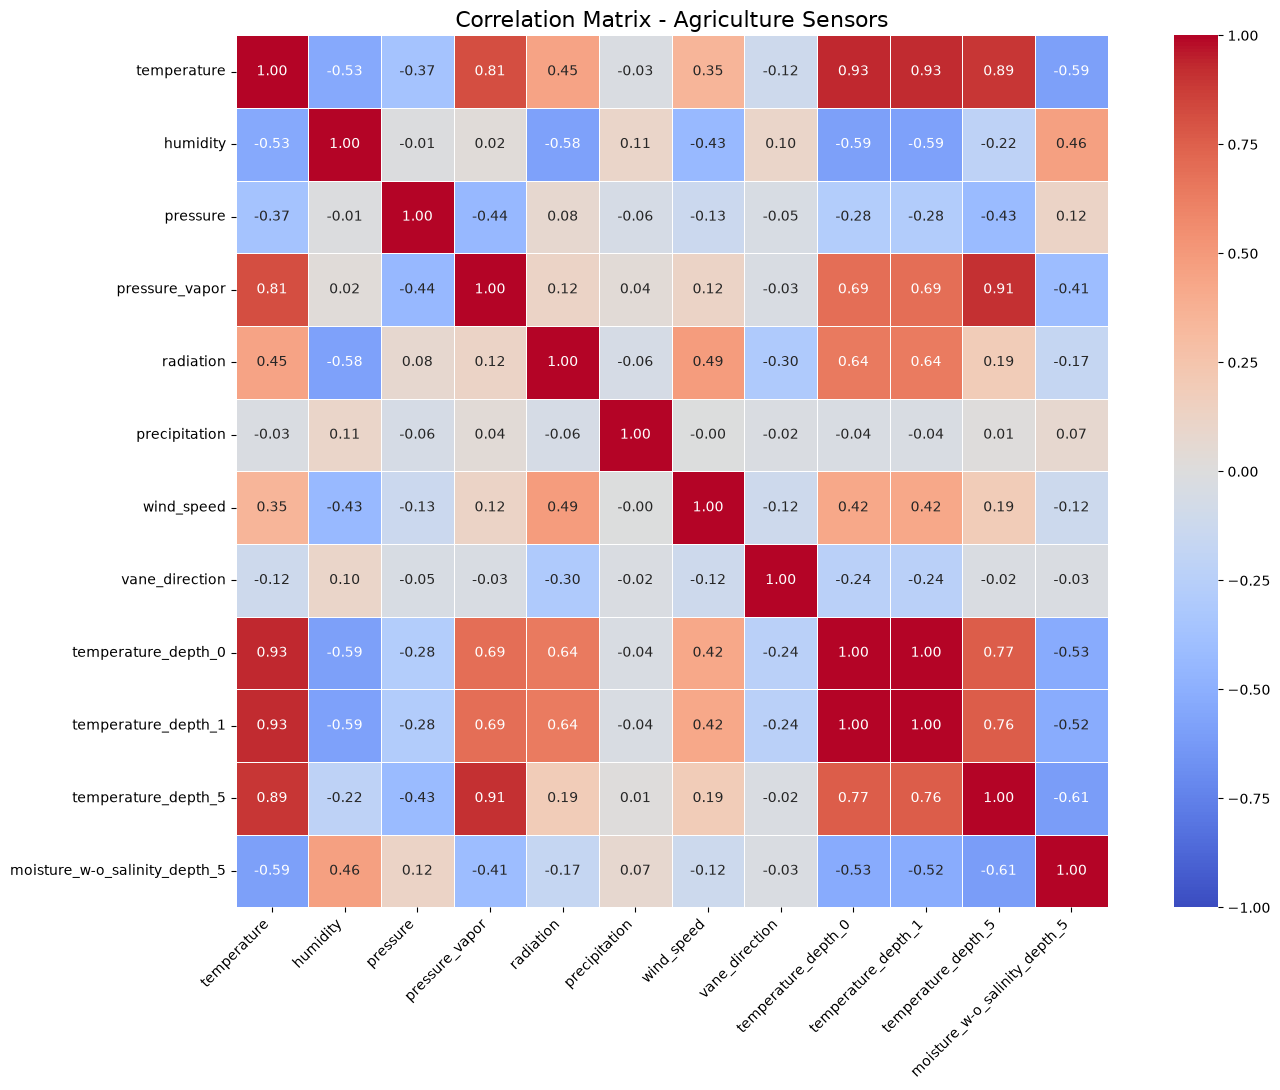

In [24]:
correlation_matrix = correlation_data.corr(method="pearson")
plt.figure(figsize=(15, 11))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)
plt.title("Correlation Matrix - Agriculture Sensors", fontsize=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Corelatii cu umiditatea solului'


,correlation
temperature_depth_5,-0.609305
temperature,-0.587363
temperature_depth_0,-0.526022
temperature_depth_1,-0.522292
humidity,0.461674
pressure_vapor,-0.407453
radiation,-0.165963
pressure,0.121043
wind_speed,-0.119166
precipitation,0.074280


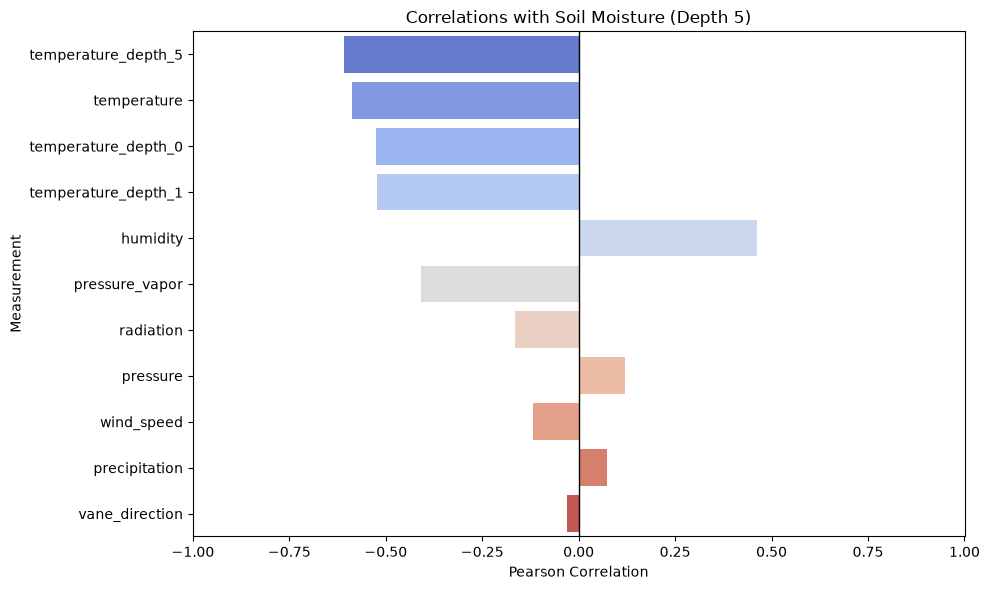

In [25]:
target = "moisture_w-o_salinity_depth_5"
soil_correlations = (
    correlation_matrix[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)
display(soil_correlations.to_frame("correlation"))
plt.figure(figsize=(10, 6))
sns.barplot(
    x=soil_correlations.values,
    y=soil_correlations.index,
    hue=soil_correlations.index,
    palette="coolwarm",
    legend=False
)
plt.axvline(0, color="black", linewidth=1)
plt.xlim(-1, 1)
plt.title("Correlations with Soil Moisture (Depth 5)")
plt.xlabel("Pearson Correlation")
plt.ylabel("Measurement")
plt.tight_layout()
plt.show()